In [1]:
import pandas as pd
df=pd.read_csv('/content/ecommerce_customer_purchase_raw_synthetic.csv')

In [2]:
df.shape

(20080, 16)

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20080 entries, 0 to 20079
Data columns (total 16 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer_ID            20080 non-null  object 
 1   Age                    19919 non-null  float64
 2   Gender                 19960 non-null  object 
 3   Location               19980 non-null  object 
 4   Device_Type            20080 non-null  object 
 5   Session_Duration       19939 non-null  float64
 6   Pages_Viewed           20080 non-null  int64  
 7   Products_Viewed        20080 non-null  int64  
 8   Cart_Added             20080 non-null  int64  
 9   Previous_Purchases     20080 non-null  int64  
 10  Total_Spending         20080 non-null  float64
 11  Discount_Used          20080 non-null  int64  
 12  Category               19980 non-null  object 
 13  Sessions_Last_30_Days  20080 non-null  int64  
 14  Customer_Engagement    19960 non-null  float64
 15  Pu

In [4]:
df.describe()

,Age,Session_Duration,Pages_Viewed,Products_Viewed,Cart_Added,Previous_Purchases,Total_Spending,Discount_Used,Sessions_Last_30_Days,Customer_Engagement,Purchase
count,19919.000000,19939.000000,20080.000000,20080.000000,20080.000000,20080.000000,20080.000000,20080.000000,20080.000000,19960.000000,20080.000000
mean,34.285004,14.988250,21.767082,11.970269,0.623904,2.404482,2697.304766,0.236952,4.988745,58.697041,0.713795
std,9.581170,8.769701,14.317304,8.390559,0.484417,1.548023,2940.749440,0.425223,2.203360,19.589606,0.451998
min,18.000000,1.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.500000,0.000000
25%,27.000000,8.550000,11.000000,6.000000,0.000000,1.000000,913.585000,0.000000,3.000000,44.230000,0.000000
50%,34.000000,13.320000,19.000000,10.000000,1.000000,2.000000,1872.340000,0.000000,5.000000,56.020000,1.000000
75%,41.000000,19.600000,29.000000,16.000000,1.000000,3.000000,3497.752500,0.000000,6.000000,71.082500,1.000000
max,70.000000,76.420000,120.000000,60.000000,1.000000,10.000000,55856.160000,1.000000,16.000000,100.000000,1.000000


In [5]:
df.head()

,Customer_ID,Age,Gender,Location,Device_Type,Session_Duration,Pages_Viewed,Products_Viewed,Cart_Added,Previous_Purchases,Total_Spending,Discount_Used,Category,Sessions_Last_30_Days,Customer_Engagement,Purchase
0,C116799,35.0,Female,Delhi,Mobile,22.42,31,20,1,3,1377.21,1,Home & Kitchen,6,66.09,1
1,C105149,21.0,Female,Pune,Mobile,20.03,39,28,1,0,0.00,1,Beauty,3,91.13,1
2,C117970,45.0,Female,Hyderabad,Desktop,19.48,26,11,1,1,1253.35,0,Beauty,3,69.41,0
3,C108732,37.0,Female,Vijayawada,Mobile,34.13,26,11,1,0,0.00,0,Electronics,7,78.07,1
4,C105865,18.0,Male,Bengaluru,Mobile,21.69,30,20,1,2,2136.72,0,Electronics,5,75.98,1


In [6]:
df.tail()

,Customer_ID,Age,Gender,Location,Device_Type,Session_Duration,Pages_Viewed,Products_Viewed,Cart_Added,Previous_Purchases,Total_Spending,Discount_Used,Category,Sessions_Last_30_Days,Customer_Engagement,Purchase
20075,C111284,32.0,Male,Chennai,Mobile,16.96,26,9,1,2,2406.73,0,Beauty,1,68.35,1
20076,C111964,26.0,Male,Delhi,Mobile,13.81,25,16,1,3,2727.76,0,Electronics,5,66.60,1
20077,C105390,50.0,Male,Bengaluru,Desktop,14.89,22,13,1,4,5686.15,0,Home & Kitchen,8,62.52,1
20078,C100860,24.0,Female,Other,Mobile,6.13,9,4,1,1,527.51,0,Sports,6,36.90,1
20079,C115795,44.0,Female,Bengaluru,Desktop,10.59,20,14,0,5,2182.48,0,Grocery,6,51.50,1


In [7]:
df.isnull().sum()

,0
Customer_ID,0
Age,161
Gender,120
Location,100
Device_Type,0
Session_Duration,141
Pages_Viewed,0
Products_Viewed,0
Cart_Added,0
Previous_Purchases,0


In [8]:
df.duplicated().sum()

np.int64(80)

In [9]:
df.nunique()

,0
Customer_ID,20000
Age,53
Gender,3
Location,10
Device_Type,3
Session_Duration,3686
Pages_Viewed,106
Products_Viewed,60
Cart_Added,2
Previous_Purchases,11


In [10]:
#SDuplicate Customer IDs
df["Customer_ID"].duplicated().sum()

np.int64(80)

In [11]:
df_clean = df.copy()

In [12]:
# Numerical columns - fill missing values with median
numeric_cols = ['Age', 'Session_Duration', 'Customer_Engagement']

for col in numeric_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].median())

In [13]:
# Categorical columns - fill missing values with mode
categorical_cols = ['Gender', 'Location', 'Category']

for col in categorical_cols:
    df_clean[col] = df_clean[col].fillna(df_clean[col].mode()[0])

In [14]:
df_clean.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,0
Location,0
Device_Type,0
Session_Duration,0
Pages_Viewed,0
Products_Viewed,0
Cart_Added,0
Previous_Purchases,0


In [15]:
# Remove exact duplicate records
df_clean = df_clean.drop_duplicates()

print("Duplicate rows after cleaning:", df_clean.duplicated().sum())
print("New dataset shape:", df_clean.shape)

Duplicate rows after cleaning: 0
New dataset shape: (20000, 16)


In [16]:
df_clean.isnull().sum()

,0
Customer_ID,0
Age,0
Gender,0
Location,0
Device_Type,0
Session_Duration,0
Pages_Viewed,0
Products_Viewed,0
Cart_Added,0
Previous_Purchases,0


In [17]:
import numpy as np
# Numerical columns
numeric_cols = df_clean.select_dtypes(include=np.number).columns

df_clean[numeric_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
Age,20000.0,34.278000,9.540512,18.0,27.0000,34.000,41.0000,70.00
Session_Duration,20000.0,14.969270,8.721428,1.0,8.5900,13.320,19.5400,76.42
Pages_Viewed,20000.0,21.755250,14.291353,1.0,11.0000,19.000,29.0000,120.00
Products_Viewed,20000.0,11.964500,8.379090,1.0,6.0000,10.000,16.0000,60.00
Cart_Added,20000.0,0.624000,0.484392,0.0,0.0000,1.000,1.0000,1.00
Previous_Purchases,20000.0,2.404800,1.548824,0.0,1.0000,2.000,3.0000,10.00
Total_Spending,20000.0,2697.684964,2942.791644,0.0,912.8625,1872.465,3497.7525,55856.16
Discount_Used,20000.0,0.236850,0.425160,0.0,0.0000,0.000,0.0000,1.00
Sessions_Last_30_Days,20000.0,4.988050,2.203713,0.0,3.0000,5.000,6.0000,16.00
Customer_Engagement,20000.0,58.670495,19.520635,6.5,44.3000,56.020,70.9700,100.00


In [18]:
# Detect potential outliers using the IQR method

outlier_results = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[col] < lower_bound) |
        (df_clean[col] > upper_bound)
    ]

    outlier_results.append({
        "Feature": col,
        "Q1": Q1,
        "Q3": Q3,
        "Lower_Bound": lower_bound,
        "Upper_Bound": upper_bound,
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": round(len(outliers) / len(df_clean) * 100, 2)
    })

outlier_df = pd.DataFrame(outlier_results)

outlier_df

,Feature,Q1,Q3,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
0,Age,27.0000,41.0000,6.0000,62.0000,43,0.21
1,Session_Duration,8.5900,19.5400,-7.8350,35.9650,523,2.61
2,Pages_Viewed,11.0000,29.0000,-16.0000,56.0000,563,2.81
3,Products_Viewed,6.0000,16.0000,-9.0000,31.0000,674,3.37
4,Cart_Added,0.0000,1.0000,-1.5000,2.5000,0,0.00
5,Previous_Purchases,1.0000,3.0000,-2.0000,6.0000,241,1.21
6,Total_Spending,912.8625,3497.7525,-2964.4725,7375.0875,1224,6.12
7,Discount_Used,0.0000,0.0000,0.0000,0.0000,4737,23.69
8,Sessions_Last_30_Days,3.0000,6.0000,-1.5000,10.5000,247,1.23
9,Customer_Engagement,44.3000,70.9700,4.2950,110.9750,0,0.00


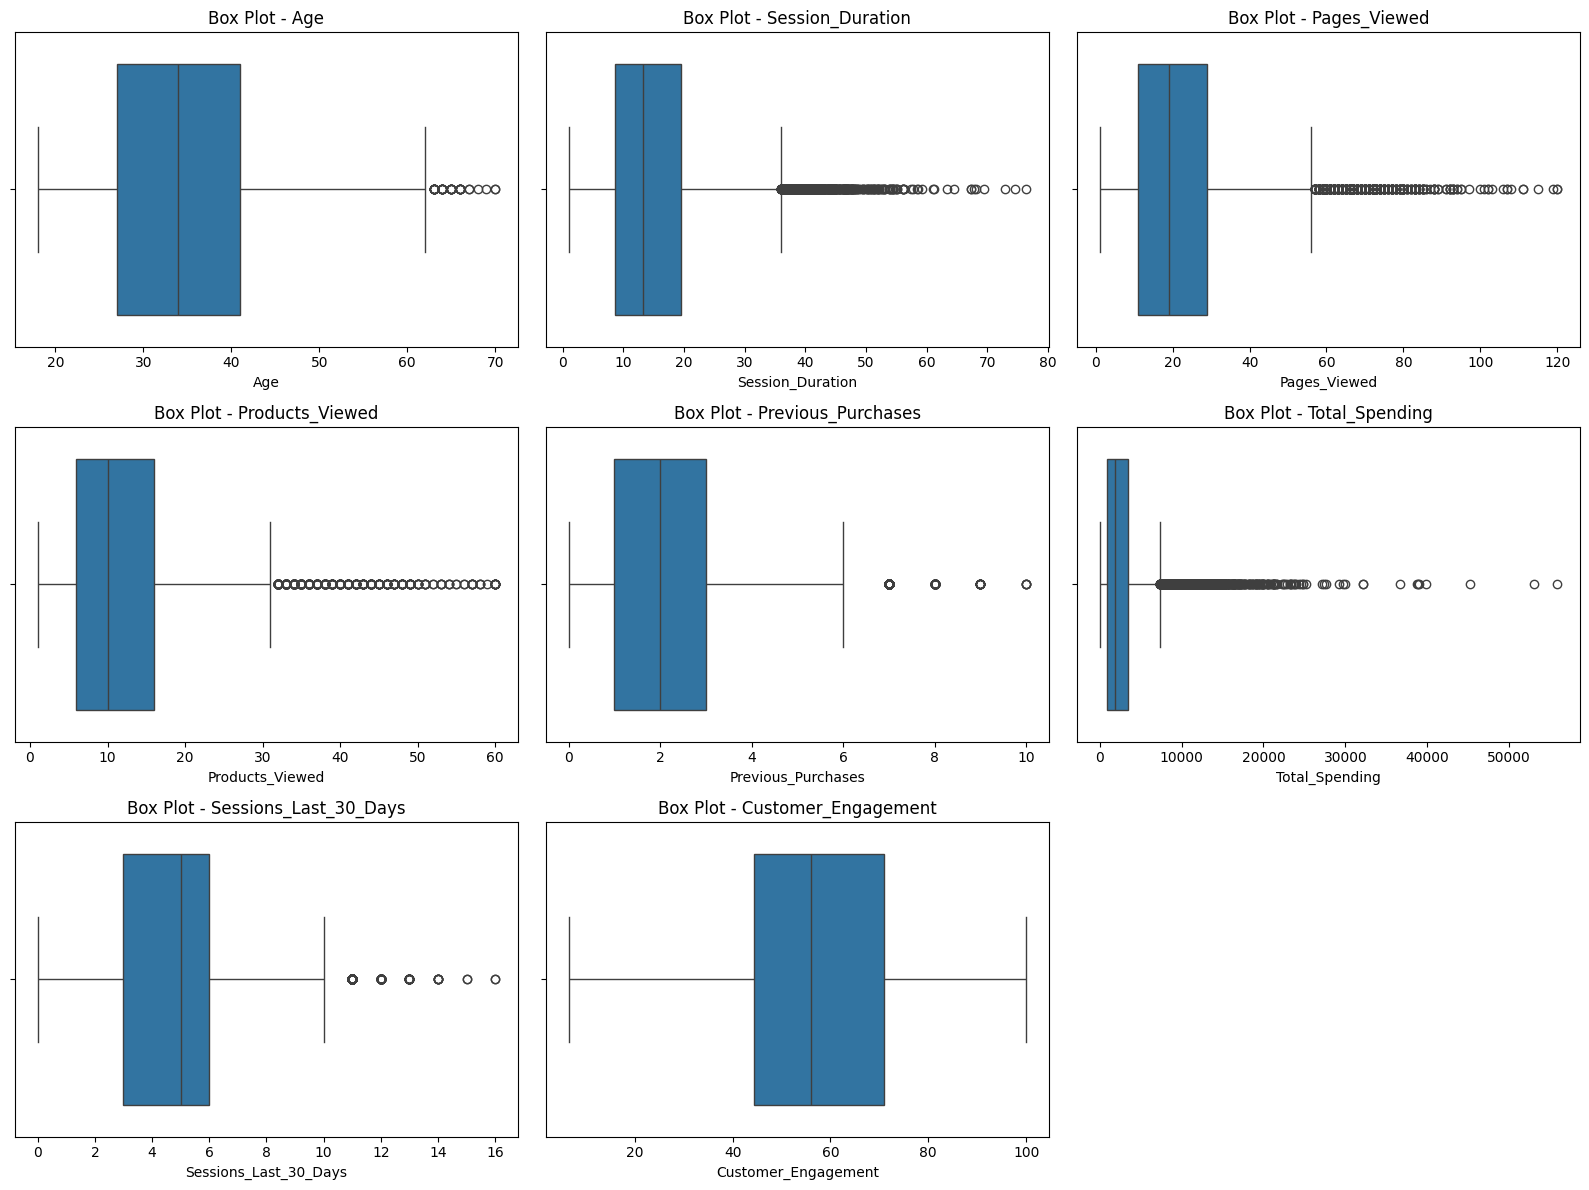

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns

features_to_plot = [
    'Age',
    'Session_Duration',
    'Pages_Viewed',
    'Products_Viewed',
    'Previous_Purchases',
    'Total_Spending',
    'Sessions_Last_30_Days',
    'Customer_Engagement'
]

plt.figure(figsize=(16, 12))

for i, col in enumerate(features_to_plot, 1):
    plt.subplot(3, 3, i)
    sns.boxplot(x=df_clean[col])
    plt.title(f'Box Plot - {col}')

plt.tight_layout()
plt.show()

In [20]:
# Check minimum and maximum values of important numerical features

checks = {
    'Age': (df_clean['Age'].min(), df_clean['Age'].max()),
    'Session_Duration': (df_clean['Session_Duration'].min(), df_clean['Session_Duration'].max()),
    'Pages_Viewed': (df_clean['Pages_Viewed'].min(), df_clean['Pages_Viewed'].max()),
    'Products_Viewed': (df_clean['Products_Viewed'].min(), df_clean['Products_Viewed'].max()),
    'Previous_Purchases': (df_clean['Previous_Purchases'].min(), df_clean['Previous_Purchases'].max()),
    'Total_Spending': (df_clean['Total_Spending'].min(), df_clean['Total_Spending'].max()),
    'Sessions_Last_30_Days': (df_clean['Sessions_Last_30_Days'].min(), df_clean['Sessions_Last_30_Days'].max()),
    'Customer_Engagement': (df_clean['Customer_Engagement'].min(), df_clean['Customer_Engagement'].max())
}

pd.DataFrame(checks, index=['Minimum', 'Maximum']).T

,Minimum,Maximum
Age,18.0,70.00
Session_Duration,1.0,76.42
Pages_Viewed,1.0,120.00
Products_Viewed,1.0,60.00
Previous_Purchases,0.0,10.00
Total_Spending,0.0,55856.16
Sessions_Last_30_Days,0.0,16.00
Customer_Engagement,6.5,100.00


EDA-exploratory data analysis


In [21]:
# Purchase distribution

purchase_counts = df_clean['Purchase'].value_counts()

print(purchase_counts)

Purchase
1    14273
0     5727
Name: count, dtype: int64


In [22]:
purchase_percentage = df_clean['Purchase'].value_counts(normalize=True) * 100

print(purchase_percentage)

Purchase
1    71.365
0    28.635
Name: proportion, dtype: float64


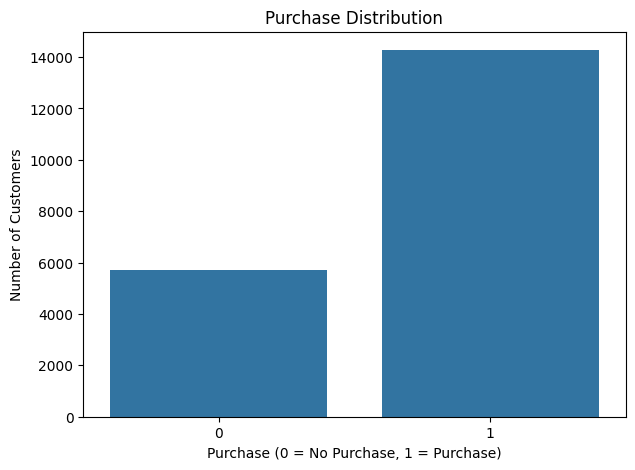

In [23]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df_clean, x='Purchase')

plt.title('Purchase Distribution')
plt.xlabel('Purchase (0 = No Purchase, 1 = Purchase)')
plt.ylabel('Number of Customers')

plt.show()

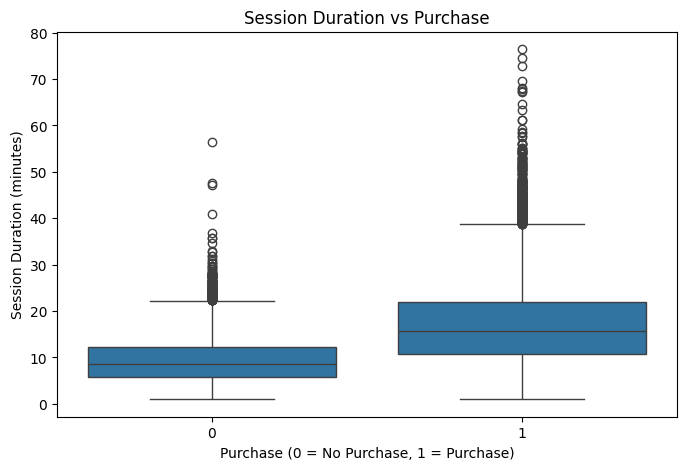

In [24]:
#Does session duration influence purchasing?
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Purchase',
    y='Session_Duration'
)

plt.title('Session Duration vs Purchase')
plt.xlabel('Purchase (0 = No Purchase, 1 = Purchase)')
plt.ylabel('Session Duration (minutes)')

plt.show()

In [25]:
session_purchase_summary = df_clean.groupby('Purchase')['Session_Duration'].agg(
    ['count', 'mean', 'median']
)

session_purchase_summary

,count,mean,median
Purchase,,,
0,5727,9.537933,8.65
1,14273,17.148578,15.63


In [26]:
#Does the number of products viewed affect purchasing?
products_purchase_summary = df_clean.groupby('Purchase')['Products_Viewed'].agg(
    ['count', 'mean', 'median']
)

products_purchase_summary

,count,mean,median
Purchase,,,
0,5727,6.707351,6.0
1,14273,14.073916,12.0


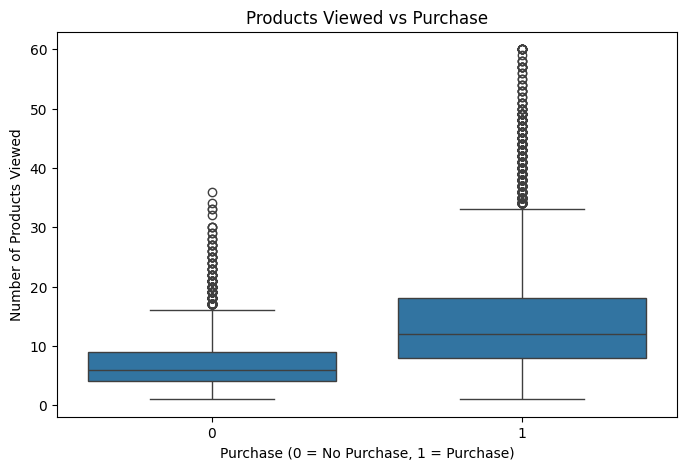

In [27]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Purchase',
    y='Products_Viewed'
)

plt.title('Products Viewed vs Purchase')
plt.xlabel('Purchase (0 = No Purchase, 1 = Purchase)')
plt.ylabel('Number of Products Viewed')

plt.show()

In [28]:
#Cart Added vs Purchase
cart_purchase_rate = (
    df_clean.groupby('Cart_Added')['Purchase']
    .mean()
    .mul(100)
    .reset_index()
)

cart_purchase_rate

,Cart_Added,Purchase
0,0,45.930851
1,1,86.690705


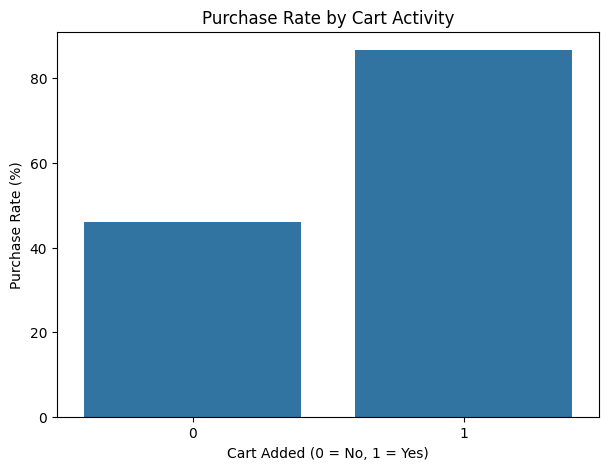

In [29]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=cart_purchase_rate,
    x='Cart_Added',
    y='Purchase'
)

plt.title('Purchase Rate by Cart Activity')
plt.xlabel('Cart Added (0 = No, 1 = Yes)')
plt.ylabel('Purchase Rate (%)')

plt.show()

In [30]:
#Device Type vs Purchase
device_purchase_rate = (
    df_clean.groupby('Device_Type')['Purchase']
    .mean()
    .mul(100)
    .reset_index()
)

device_purchase_rate

,Device_Type,Purchase
0,Desktop,72.018634
1,Mobile,71.266360
2,Tablet,69.846762


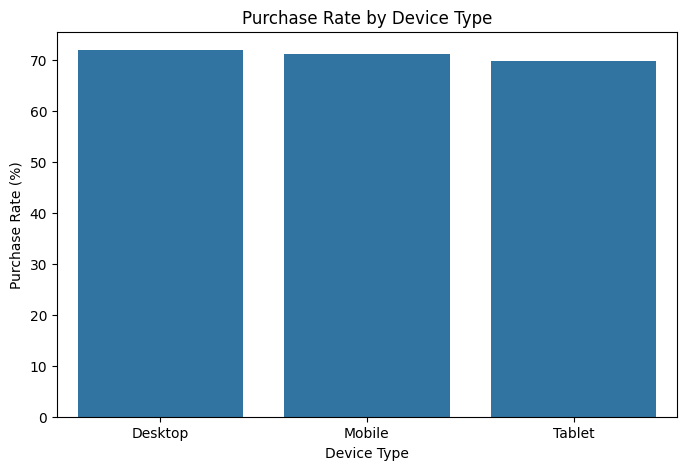

In [31]:
plt.figure(figsize=(8, 5))

sns.barplot(
    data=device_purchase_rate,
    x='Device_Type',
    y='Purchase'
)

plt.title('Purchase Rate by Device Type')
plt.xlabel('Device Type')
plt.ylabel('Purchase Rate (%)')

plt.show()

In [32]:
#Does discount usage influence purchasing behavior?
discount_purchase_rate = (
    df_clean.groupby('Discount_Used')['Purchase']
    .mean()
    .mul(100)
    .reset_index()
)

discount_purchase_rate

,Discount_Used,Purchase
0,0,70.595558
1,1,73.844205


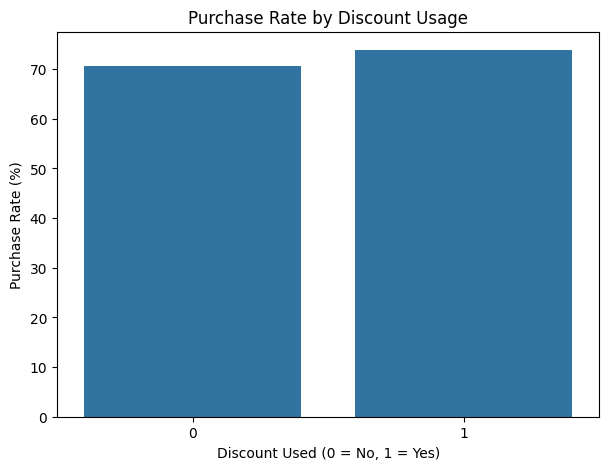

In [33]:
plt.figure(figsize=(7, 5))

sns.barplot(
    data=discount_purchase_rate,
    x='Discount_Used',
    y='Purchase'
)

plt.title('Purchase Rate by Discount Usage')
plt.xlabel('Discount Used (0 = No, 1 = Yes)')
plt.ylabel('Purchase Rate (%)')

plt.show()

In [34]:
#Which product categories have higher conversion
category_purchase_rate = (
    df_clean.groupby('Category')['Purchase']
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .reset_index()
)

category_purchase_rate

,Category,Purchase
0,Electronics,72.214810
1,Grocery,72.165370
2,Accessories,71.912988
3,Home & Kitchen,71.551155
4,Books,71.495571
5,Beauty,71.434443
6,Sports,70.368501
7,Fashion,70.162400


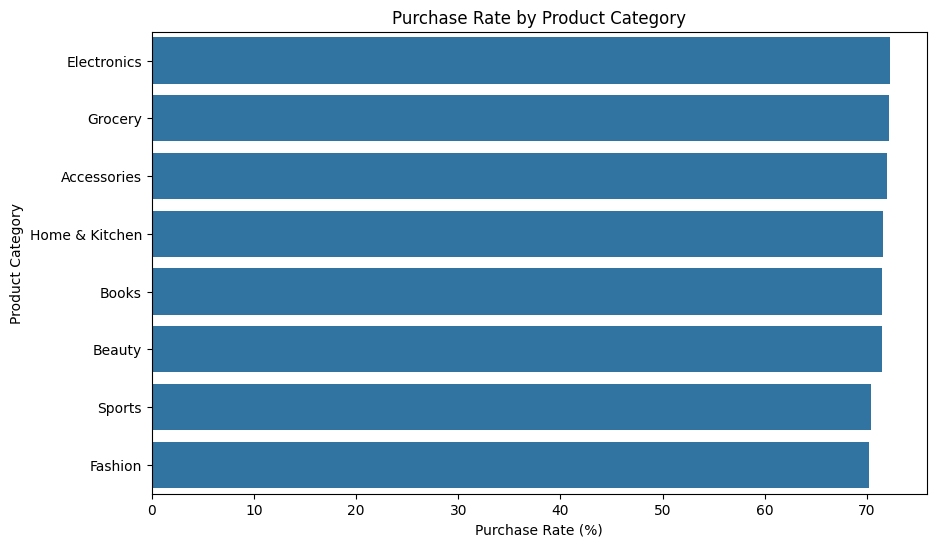

In [35]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=category_purchase_rate,
    x='Purchase',
    y='Category'
)

plt.title('Purchase Rate by Product Category')
plt.xlabel('Purchase Rate (%)')
plt.ylabel('Product Category')

plt.show()

In [36]:
#Does previous purchase history affect future purchases?
previous_purchase_rate = (
    df_clean.groupby('Previous_Purchases')['Purchase']
    .mean()
    .mul(100)
    .reset_index()
)

previous_purchase_rate

,Previous_Purchases,Purchase
0,0,67.367257
1,1,68.936567
2,2,71.263933
3,3,72.395709
4,4,72.423510
5,5,78.211382
6,6,73.318872
7,7,81.818182
8,8,74.137931
9,9,64.285714


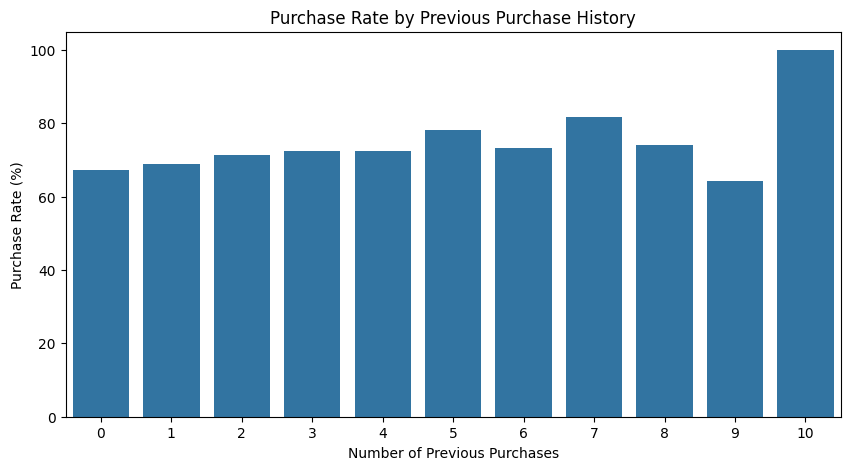

In [37]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=previous_purchase_rate,
    x='Previous_Purchases',
    y='Purchase'
)

plt.title('Purchase Rate by Previous Purchase History')
plt.xlabel('Number of Previous Purchases')
plt.ylabel('Purchase Rate (%)')

plt.show()

In [38]:
#What relationship exists between customer engagement and purchasing?
engagement_purchase_summary = (
    df_clean.groupby('Purchase')['Customer_Engagement']
    .agg(['count', 'mean', 'median'])
)

engagement_purchase_summary

,count,mean,median
Purchase,,,
0,5727,44.974831,44.01
1,14273,64.165840,62.01


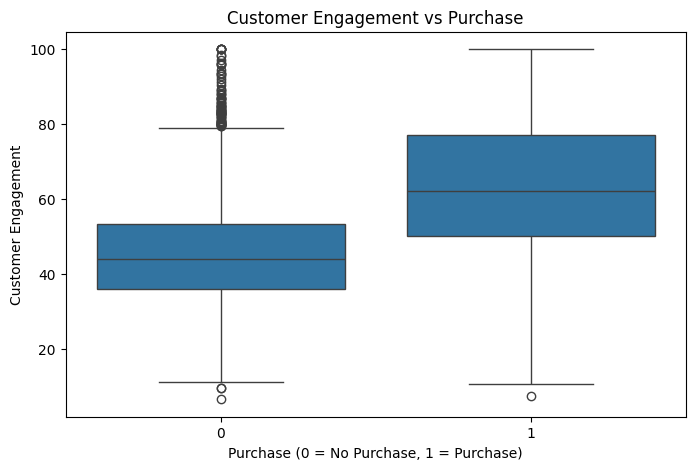

In [39]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df_clean,
    x='Purchase',
    y='Customer_Engagement'
)

plt.title('Customer Engagement vs Purchase')
plt.xlabel('Purchase (0 = No Purchase, 1 = Purchase)')
plt.ylabel('Customer Engagement')

plt.show()

In [40]:
#corelation with engagement
engagement_correlation = df_clean[
    ['Customer_Engagement', 'Purchase']
].corr()

engagement_correlation

,Customer_Engagement,Purchase
Customer_Engagement,1.000000,0.444433
Purchase,0.444433,1.000000


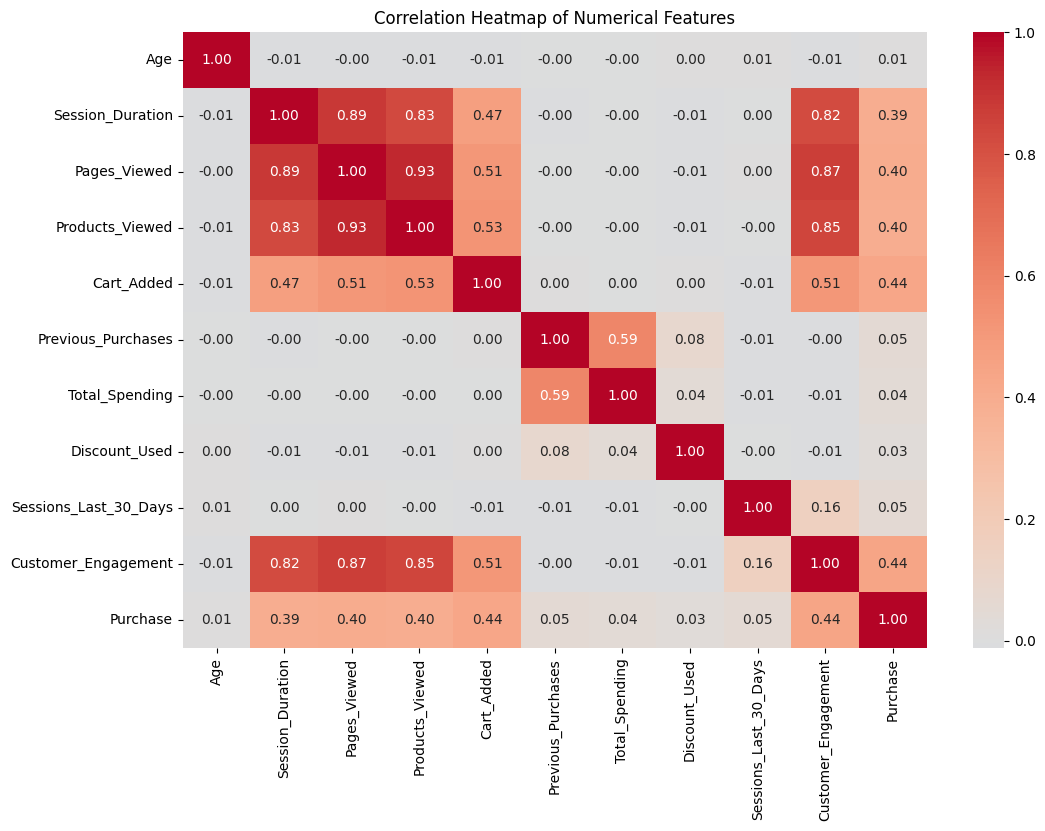

In [41]:
#corelation heatmap
plt.figure(figsize=(12,8))

correlation_matrix = df_clean.select_dtypes(include=np.number).corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap of Numerical Features')

plt.show()

FEATURE ENGINEERING

In [42]:
# Separate features and target
#Customer_ID is an identifier, not a behavioral feature, so we should not give it to the ML model.

X = df_clean.drop(columns=['Purchase', 'Customer_ID'])
y = df_clean['Purchase']

print("Features:", X.columns.tolist())
print("\nTarget:", y.name)

Features: ['Age', 'Gender', 'Location', 'Device_Type', 'Session_Duration', 'Pages_Viewed', 'Products_Viewed', 'Cart_Added', 'Previous_Purchases', 'Total_Spending', 'Discount_Used', 'Category', 'Sessions_Last_30_Days', 'Customer_Engagement']

Target: Purchase


In [43]:
# Identify numerical and categorical features

numerical_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include='object').columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Session_Duration', 'Pages_Viewed', 'Products_Viewed', 'Cart_Added', 'Previous_Purchases', 'Total_Spending', 'Discount_Used', 'Sessions_Last_30_Days', 'Customer_Engagement']

Categorical Features:
['Gender', 'Location', 'Device_Type', 'Category']


In [44]:
#now  adding useful features
#Pages Viewed Per Minute
X['Pages_Per_Minute'] = (
    X['Pages_Viewed'] / X['Session_Duration'].replace(0, np.nan)
)

X['Pages_Per_Minute'] = X['Pages_Per_Minute'].fillna(0)

In [45]:
#Products Viewed Per Page
X['Products_Per_Page'] = (
    X['Products_Viewed'] / X['Pages_Viewed'].replace(0, np.nan)
)

X['Products_Per_Page'] = X['Products_Per_Page'].fillna(0)

In [46]:
#Average Historical Spending
X['Avg_Spending_Per_Previous_Purchase'] = (
    X['Total_Spending'] /
    X['Previous_Purchases'].replace(0, np.nan)
)

X['Avg_Spending_Per_Previous_Purchase'] = (
    X['Avg_Spending_Per_Previous_Purchase'].fillna(0)
)

In [47]:
#Create an Engagement Category
X['Engagement_Level'] = pd.cut(
    X['Customer_Engagement'],
    bins=[-1, 40, 70, 100],
    labels=['Low', 'Medium', 'High']
)

In [48]:
#Check the new features
X.head()


,Age,Gender,Location,Device_Type,Session_Duration,Pages_Viewed,Products_Viewed,Cart_Added,Previous_Purchases,Total_Spending,Discount_Used,Category,Sessions_Last_30_Days,Customer_Engagement,Pages_Per_Minute,Products_Per_Page,Avg_Spending_Per_Previous_Purchase,Engagement_Level
0,35.0,Female,Delhi,Mobile,22.42,31,20,1,3,1377.21,1,Home & Kitchen,6,66.09,1.382694,0.645161,459.07,Medium
1,21.0,Female,Pune,Mobile,20.03,39,28,1,0,0.00,1,Beauty,3,91.13,1.947079,0.717949,0.00,High
2,45.0,Female,Hyderabad,Desktop,19.48,26,11,1,1,1253.35,0,Beauty,3,69.41,1.334702,0.423077,1253.35,Medium
3,37.0,Female,Vijayawada,Mobile,34.13,26,11,1,0,0.00,0,Electronics,7,78.07,0.761793,0.423077,0.00,High
4,18.0,Male,Bengaluru,Mobile,21.69,30,20,1,2,2136.72,0,Electronics,5,75.98,1.383126,0.666667,1068.36,High


In [49]:
print("New shape:", X.shape)

New shape: (20000, 18)


In [50]:
X[['Pages_Per_Minute',
   'Products_Per_Page',
   'Avg_Spending_Per_Previous_Purchase',
   'Engagement_Level']].describe(include='all')

,Pages_Per_Minute,Products_Per_Page,Avg_Spending_Per_Previous_Purchase,Engagement_Level
count,20000.000000,20000.000000,20000.000000,20000
unique,NaN,NaN,NaN,3
top,NaN,NaN,NaN,Medium
freq,NaN,NaN,NaN,11302
mean,1.453914,0.552928,1021.127109,NaN
std,0.441330,0.125440,851.667628,NaN
min,0.065020,0.250000,0.000000,NaN
25%,1.169814,0.450000,491.470000,NaN
50%,1.449954,0.550000,834.466667,NaN
75%,1.724138,0.657895,1336.062500,NaN


In [51]:
#Check whether our new features contain missing values
X.isnull().sum()

,0
Age,0
Gender,0
Location,0
Device_Type,0
Session_Duration,0
Pages_Viewed,0
Products_Viewed,0
Cart_Added,0
Previous_Purchases,0
Total_Spending,0


Train/Test Split + Preprocessing

In [52]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16000, 18)
Testing data: (4000, 18)


In [53]:
#Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['Age', 'Session_Duration', 'Pages_Viewed', 'Products_Viewed', 'Cart_Added', 'Previous_Purchases', 'Total_Spending', 'Discount_Used', 'Sessions_Last_30_Days', 'Customer_Engagement', 'Pages_Per_Minute', 'Products_Per_Page', 'Avg_Spending_Per_Previous_Purchase']

Categorical features:
['Gender', 'Location', 'Device_Type', 'Category', 'Engagement_Level']


In [54]:
#Create the preprocessing pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ]
)

In [55]:
#check split
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True))

X_train: (16000, 18)
X_test : (4000, 18)
y_train: (16000,)
y_test : (4000,)

Training target distribution:
Purchase
1    0.713625
0    0.286375
Name: proportion, dtype: float64

Testing target distribution:
Purchase
1    0.71375
0    0.28625
Name: proportion, dtype: float64


In [56]:
#Create the Logistic Regression pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', LogisticRegression(max_iter=1000))
    ]
)

In [57]:
logistic_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Session_Duration',
                                                   'Pages_Viewed',
                                                   'Products_Viewed',
                                                   'Cart_Added',
                                                   'Previous_Purchases',
                                                   'Total_Spending',
                                                   'Discount_Used',
                                                   'Sessions_Last_30_Days',
                                                   'Customer_Engagement',
                                                   'Pages_Per_Minute',
                                                   'Products_Per_Page',
                                                   'Avg_Spending_Per_Previous_Purchase']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Location',
                                                   'Device_Type', 'Category',
                                                   'Engagement_Level'])])),
                ('model', LogisticRegression(max_iter=1000))])

In [58]:
y_pred = logistic_model.predict(X_test)

In [59]:
y_prob = logistic_model.predict_proba(X_test)[:, 1]

In [60]:
#Evaluate the baseline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Accuracy :", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall   :", recall_score(y_test, y_pred))
print("F1 Score :", f1_score(y_test, y_pred))
print("ROC-AUC  :", roc_auc_score(y_test, y_prob))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy : 0.77275
Precision: 0.8183900523560209
Recall   : 0.8760070052539405
F1 Score : 0.8462189138893588
ROC-AUC  : 0.8179931018132595

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.52      0.56      1145
           1       0.82      0.88      0.85      2855

    accuracy                           0.77      4000
   macro avg       0.72      0.70      0.71      4000
weighted avg       0.76      0.77      0.77      4000



In [61]:
baseline_results = pd.DataFrame({
    'Model': ['Logistic Regression'],
    'Accuracy': [accuracy_score(y_test, y_pred)],
    'Precision': [precision_score(y_test, y_pred)],
    'Recall': [recall_score(y_test, y_pred)],
    'F1_Score': [f1_score(y_test, y_pred)],
    'ROC_AUC': [roc_auc_score(y_test, y_prob)]
})

baseline_results

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.77275,0.81839,0.876007,0.846219,0.817993


Decison tree classifier

In [62]:
#Create the Decision Tree pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

decision_tree_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', DecisionTreeClassifier(
            random_state=42,
            max_depth=5
        ))
    ]
)

In [63]:
decision_tree_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Session_Duration',
                                                   'Pages_Viewed',
                                                   'Products_Viewed',
                                                   'Cart_Added',
                                                   'Previous_Purchases',
                                                   'Total_Spending',
                                                   'Discount_Used',
                                                   'Sessions_Last_30_Days',
                                                   'Customer_Engagement',
                                                   'Pages_Per_Minute',
                                                   'Products_Per_Page',
                                                   'Avg_Spending_Per_Previous_Purchase']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Location',
                                                   'Device_Type', 'Category',
                                                   'Engagement_Level'])])),
                ('model',
                 DecisionTreeClassifier(max_depth=5, random_state=42))])

In [64]:
dt_pred = decision_tree_model.predict(X_test)

dt_prob = decision_tree_model.predict_proba(X_test)[:, 1]

In [65]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)

print("Decision Tree Results")

print("Accuracy :", accuracy_score(y_test, dt_pred))
print("Precision:", precision_score(y_test, dt_pred))
print("Recall   :", recall_score(y_test, dt_pred))
print("F1 Score :", f1_score(y_test, dt_pred))
print("ROC-AUC  :", roc_auc_score(y_test, dt_prob))

print("\nClassification Report:")
print(classification_report(y_test, dt_pred))

Decision Tree Results
Accuracy : 0.76725
Precision: 0.8077415227127319
Recall   : 0.8844133099824869
F1 Score : 0.8443404113024577
ROC-AUC  : 0.8111232114041864

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.48      0.54      1145
           1       0.81      0.88      0.84      2855

    accuracy                           0.77      4000
   macro avg       0.72      0.68      0.69      4000
weighted avg       0.75      0.77      0.76      4000



In [66]:
#camparision between logistic regression and decision tree
dt_results = pd.DataFrame({
    'Model': ['Decision Tree'],
    'Accuracy': [accuracy_score(y_test, dt_pred)],
    'Precision': [precision_score(y_test, dt_pred)],
    'Recall': [recall_score(y_test, dt_pred)],
    'F1_Score': [f1_score(y_test, dt_pred)],
    'ROC_AUC': [roc_auc_score(y_test, dt_prob)]
})

model_results = pd.concat(
    [baseline_results, dt_results],
    ignore_index=True
)

model_results

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.77275,0.818390,0.876007,0.846219,0.817993
1,Decision Tree,0.76725,0.807742,0.884413,0.844340,0.811123


Random forest classifier

In [67]:
#Create the Random Forest pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestClassifier(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [68]:
random_forest_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Session_Duration',
                                                   'Pages_Viewed',
                                                   'Products_Viewed',
                                                   'Cart_Added',
                                                   'Previous_Purchases',
                                                   'Total_Spending',
                                                   'Discount_Used',
                                                   'Sessions_Last_30_Days',
                                                   'Customer_Engagement',
                                                   'Pages_Per_Minute',
                                                   'Products_Per_Page',
                                                   'Avg_Spending_Per_Previous_Purchase']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Location',
                                                   'Device_Type', 'Category',
                                                   'Engagement_Level'])])),
                ('model',
                 RandomForestClassifier(n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [69]:
rf_pred = random_forest_model.predict(X_test)

rf_prob = random_forest_model.predict_proba(X_test)[:, 1]

In [70]:
rf_accuracy = accuracy_score(y_test, rf_pred)
rf_precision = precision_score(y_test, rf_pred)
rf_recall = recall_score(y_test, rf_pred)
rf_f1 = f1_score(y_test, rf_pred)
rf_roc_auc = roc_auc_score(y_test, rf_prob)

print("Random Forest Results")

print("Accuracy :", rf_accuracy)
print("Precision:", rf_precision)
print("Recall   :", rf_recall)
print("F1 Score :", rf_f1)
print("ROC-AUC  :", rf_roc_auc)

print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Results
Accuracy : 0.7685
Precision: 0.8116316639741519
Recall   : 0.8798598949211909
F1 Score : 0.8443697478991596
ROC-AUC  : 0.8122484876758005

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.49      0.55      1145
           1       0.81      0.88      0.84      2855

    accuracy                           0.77      4000
   macro avg       0.72      0.69      0.70      4000
weighted avg       0.76      0.77      0.76      4000



In [71]:
rf_results = pd.DataFrame({
    'Model': ['Random Forest'],
    'Accuracy': [rf_accuracy],
    'Precision': [rf_precision],
    'Recall': [rf_recall],
    'F1_Score': [rf_f1],
    'ROC_AUC': [rf_roc_auc]
})

model_results = pd.concat(
    [model_results, rf_results],
    ignore_index=True
)

model_results

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.77275,0.818390,0.876007,0.846219,0.817993
1,Decision Tree,0.76725,0.807742,0.884413,0.844340,0.811123
2,Random Forest,0.76850,0.811632,0.879860,0.844370,0.812248


In [72]:
#cross validation
from sklearn.model_selection import StratifiedKFold, cross_val_score

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "Random Forest": random_forest_model
}

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring='roc_auc',
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "CV_Mean_ROC_AUC": scores.mean(),
        "CV_Std_ROC_AUC": scores.std()
    })

cv_results_df = pd.DataFrame(cv_results)

print(cv_results_df)

                 Model  CV_Mean_ROC_AUC  CV_Std_ROC_AUC
0  Logistic Regression         0.831048        0.004680
1        Decision Tree         0.820179        0.003574
2        Random Forest         0.823864        0.003942


In [73]:
#hyperparameter tuninng
from sklearn.model_selection import GridSearchCV

rf_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestClassifier(
        random_state=42,
        n_jobs=-1
    ))
])

param_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [None, 10, 20],
    'model__min_samples_split': [2, 5],
    'model__min_samples_leaf': [1, 2]
}

grid_search = GridSearchCV(
    estimator=rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation ROC-AUC:")
print(grid_search.best_score_)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Best Parameters:
{'model__max_depth': 10, 'model__min_samples_leaf': 2, 'model__min_samples_split': 2, 'model__n_estimators': 200}

Best Cross-Validation ROC-AUC:
0.8278393271714597


In [74]:
#Evaluate the Tuned Random Forest
# Get the best tuned model
tuned_rf_model = grid_search.best_estimator_

# Predictions on the test set
tuned_rf_pred = tuned_rf_model.predict(X_test)
tuned_rf_prob = tuned_rf_model.predict_proba(X_test)[:, 1]

# Evaluation metrics
tuned_rf_accuracy = accuracy_score(y_test, tuned_rf_pred)
tuned_rf_precision = precision_score(y_test, tuned_rf_pred)
tuned_rf_recall = recall_score(y_test, tuned_rf_pred)
tuned_rf_f1 = f1_score(y_test, tuned_rf_pred)
tuned_rf_roc_auc = roc_auc_score(y_test, tuned_rf_prob)

print("Tuned Random Forest Results")
print("---------------------------")
print("Accuracy :", tuned_rf_accuracy)
print("Precision:", tuned_rf_precision)
print("Recall   :", tuned_rf_recall)
print("F1 Score :", tuned_rf_f1)
print("ROC-AUC  :", tuned_rf_roc_auc)

print("\nClassification Report:")
print(classification_report(y_test, tuned_rf_pred))

Tuned Random Forest Results
---------------------------
Accuracy : 0.77
Precision: 0.8084156837743066
Recall   : 0.8882661996497373
F1 Score : 0.8464619492656876
ROC-AUC  : 0.81522495583478

Classification Report:
              precision    recall  f1-score   support

           0       0.63      0.48      0.54      1145
           1       0.81      0.89      0.85      2855

    accuracy                           0.77      4000
   macro avg       0.72      0.68      0.69      4000
weighted avg       0.76      0.77      0.76      4000



In [75]:
improvement_results = pd.DataFrame({
    "Model": [
        "Random Forest - Baseline",
        "Random Forest - Tuned"
    ],
    "Accuracy": [
        rf_accuracy,
        tuned_rf_accuracy
    ],
    "Precision": [
        rf_precision,
        tuned_rf_precision
    ],
    "Recall": [
        rf_recall,
        tuned_rf_recall
    ],
    "F1_Score": [
        rf_f1,
        tuned_rf_f1
    ],
    "ROC_AUC": [
        rf_roc_auc,
        tuned_rf_roc_auc
    ]
})

improvement_results

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Random Forest - Baseline,0.7685,0.811632,0.879860,0.844370,0.812248
1,Random Forest - Tuned,0.7700,0.808416,0.888266,0.846462,0.815225


Confusion Matrix:
[[ 544  601]
 [ 319 2536]]


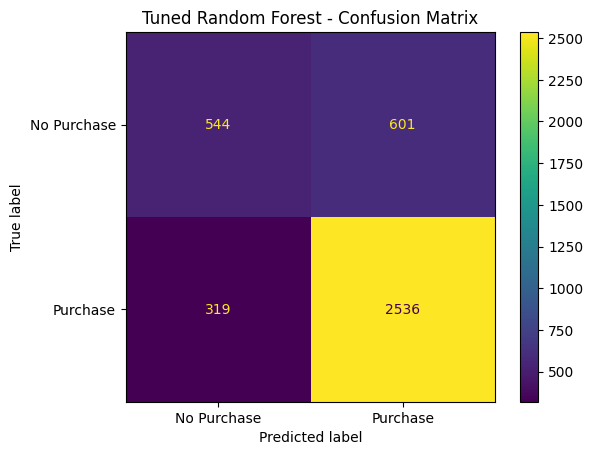

In [76]:
#confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, tuned_rf_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Purchase", "Purchase"]
)

disp.plot()
plt.title("Tuned Random Forest - Confusion Matrix")
plt.show()

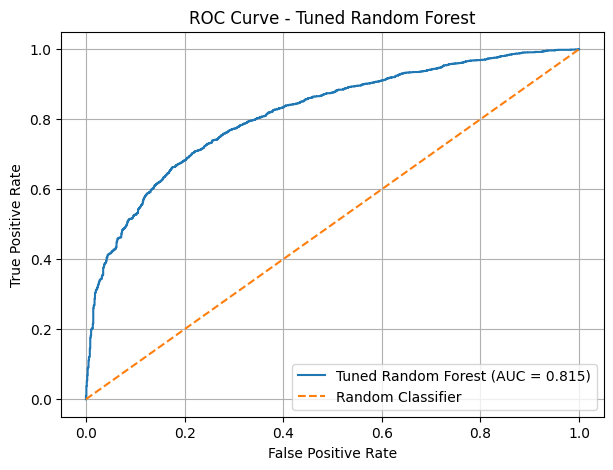

In [77]:
#roc curve
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, thresholds = roc_curve(y_test, tuned_rf_prob)
auc_score = roc_auc_score(y_test, tuned_rf_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Tuned Random Forest (AUC = {auc_score:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Tuned Random Forest")
plt.legend()
plt.grid()
plt.show()

In [78]:
#explainability
# Get the fitted preprocessor
fitted_preprocessor = tuned_rf_model.named_steps['preprocessor']

# Get the fitted Random Forest
rf_classifier = tuned_rf_model.named_steps['model']

# Get feature names after preprocessing
feature_names = fitted_preprocessor.get_feature_names_out()

# Get feature importance values
importance_values = rf_classifier.feature_importances_

# Create feature importance DataFrame
feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance_values
})

# Sort by importance
feature_importance_df = feature_importance_df.sort_values(
    by='Importance',
    ascending=False
)

feature_importance_df.head(15)

,Feature,Importance
4,num__Cart_Added,0.172824
9,num__Customer_Engagement,0.152724
3,num__Products_Viewed,0.120073
2,num__Pages_Viewed,0.101195
1,num__Session_Duration,0.097372
38,cat__Engagement_Level_Low,0.047530
37,cat__Engagement_Level_High,0.040119
10,num__Pages_Per_Minute,0.037144
6,num__Total_Spending,0.030922
12,num__Avg_Spending_Per_Previous_Purchase,0.029944


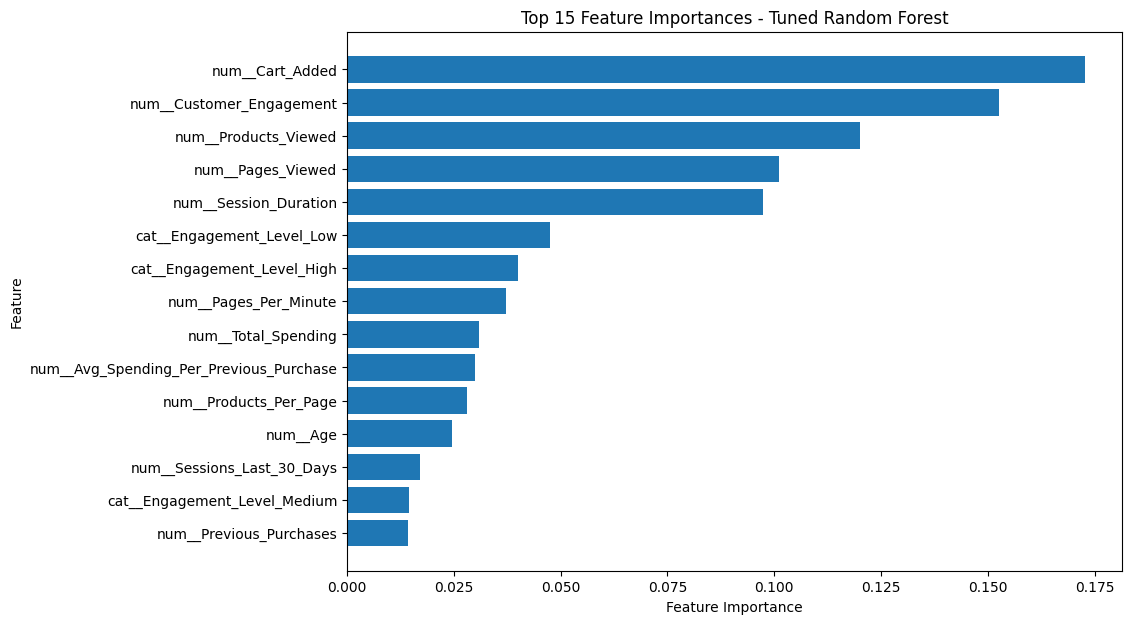

In [79]:
top_features = feature_importance_df.head(15).sort_values(
    by='Importance'
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features['Feature'],
    top_features['Importance']
)

plt.xlabel('Feature Importance')
plt.ylabel('Feature')
plt.title('Top 15 Feature Importances - Tuned Random Forest')

plt.show()

In [81]:
#Let's get feature-level importance on the original features
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    tuned_rf_model,
    X_test,
    y_test,
    scoring='roc_auc',
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

permutation_importance_df = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance_Mean': perm_result.importances_mean,
    'Importance_Std': perm_result.importances_std
})

permutation_importance_df = permutation_importance_df.sort_values(
    by='Importance_Mean',
    ascending=False
)

permutation_importance_df.head(15)

,Feature,Importance_Mean,Importance_Std
7,Cart_Added,0.042661,0.003148
13,Customer_Engagement,0.017890,0.002090
17,Engagement_Level,0.008763,0.000989
4,Session_Duration,0.004269,0.001279
5,Pages_Viewed,0.002938,0.000978
6,Products_Viewed,0.002905,0.000957
9,Total_Spending,0.001183,0.000415
8,Previous_Purchases,0.000978,0.000291
16,Avg_Spending_Per_Previous_Purchase,0.000627,0.000387
12,Sessions_Last_30_Days,0.000531,0.000321


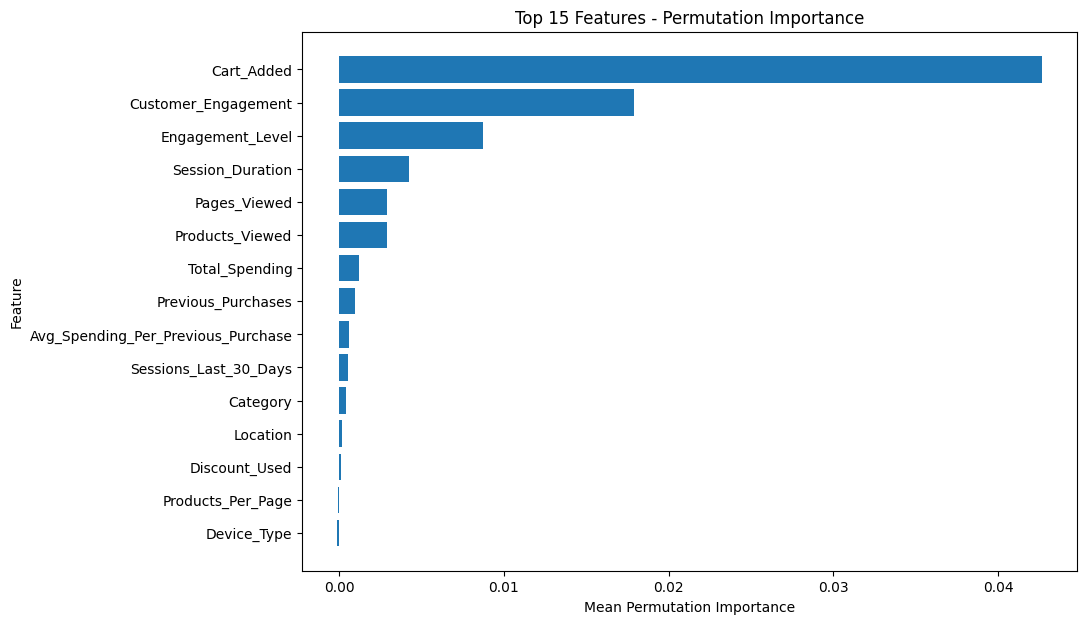

In [82]:
top_perm = permutation_importance_df.head(15).sort_values(
    by='Importance_Mean'
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_perm['Feature'],
    top_perm['Importance_Mean']
)

plt.xlabel('Mean Permutation Importance')
plt.ylabel('Feature')
plt.title('Top 15 Features - Permutation Importance')

plt.show()

In [83]:
#Predicted probability by important feature
cart_probability = pd.DataFrame({
    'Cart_Added': X_test['Cart_Added'],
    'Predicted_Probability': tuned_rf_prob
})

cart_probability.groupby('Cart_Added')['Predicted_Probability'].agg(
    ['mean', 'count']
)

,mean,count
Cart_Added,,
0,0.478096,1496
1,0.852573,2504


In [84]:
engagement_probability = pd.DataFrame({
    'Customer_Engagement': X_test['Customer_Engagement'],
    'Predicted_Probability': tuned_rf_prob
})

engagement_probability['Engagement_Band'] = pd.cut(
    engagement_probability['Customer_Engagement'],
    bins=[-1, 40, 70, 100],
    labels=['Low', 'Medium', 'High']
)

engagement_probability.groupby(
    'Engagement_Band',
    observed=True
)['Predicted_Probability'].agg(['mean', 'count'])

,mean,count
Engagement_Band,,
Low,0.380756,691
Medium,0.703944,2287
High,0.956021,1022


In [85]:
duration_probability = pd.DataFrame({
    'Session_Duration': X_test['Session_Duration'],
    'Predicted_Probability': tuned_rf_prob
})

duration_probability['Duration_Band'] = pd.qcut(
    duration_probability['Session_Duration'],
    q=4,
    duplicates='drop'
)

duration_probability.groupby(
    'Duration_Band',
    observed=True
)['Predicted_Probability'].agg(['mean', 'count'])

,mean,count
Duration_Band,,
"(1.0590000000000002, 8.44]",0.437197,1001
"(8.44, 13.15]",0.660136,1001
"(13.15, 19.385]",0.814079,998
"(19.385, 76.42]",0.939194,1000


In [86]:
#Threshold Optimization
import numpy as np
from sklearn.metrics import precision_score, recall_score, f1_score

threshold_results = []

for threshold in np.arange(0.30, 0.71, 0.05):

    threshold_pred = (tuned_rf_prob >= threshold).astype(int)

    threshold_results.append({
        'Threshold': round(threshold, 2),
        'Precision': precision_score(y_test, threshold_pred),
        'Recall': recall_score(y_test, threshold_pred),
        'F1_Score': f1_score(y_test, threshold_pred)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df

,Threshold,Precision,Recall,F1_Score
0,0.30,0.744403,0.978284,0.845467
1,0.35,0.758497,0.961471,0.848007
2,0.40,0.770863,0.941506,0.847682
3,0.45,0.789124,0.914886,0.847364
4,0.50,0.808416,0.888266,0.846462
5,0.55,0.827190,0.856743,0.841707
6,0.60,0.846827,0.813310,0.829730
7,0.65,0.869652,0.761821,0.812173
8,0.70,0.884115,0.713485,0.789688


In [87]:
final_model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest - Baseline",
        "Random Forest - Tuned"
    ],
    "Accuracy": [
        0.77275,
        0.76725,
        0.76850,
        tuned_rf_accuracy
    ],
    "Precision": [
        0.818390,
        0.807742,
        0.811632,
        tuned_rf_precision
    ],
    "Recall": [
        0.876007,
        0.884413,
        0.879860,
        tuned_rf_recall
    ],
    "F1_Score": [
        0.846219,
        0.844340,
        0.844370,
        tuned_rf_f1
    ],
    "ROC_AUC": [
        0.817993,
        0.811123,
        0.812248,
        tuned_rf_roc_auc
    ]
})

final_model_comparison

,Model,Accuracy,Precision,Recall,F1_Score,ROC_AUC
0,Logistic Regression,0.77275,0.818390,0.876007,0.846219,0.817993
1,Decision Tree,0.76725,0.807742,0.884413,0.844340,0.811123
2,Random Forest - Baseline,0.76850,0.811632,0.879860,0.844370,0.812248
3,Random Forest - Tuned,0.77000,0.808416,0.888266,0.846462,0.815225


In [88]:
#creating final predicted file
# Get the Customer_ID values corresponding to X_test
test_ids = df_clean.loc[X_test.index, 'Customer_ID']

# Use the tuned Random Forest probabilities
final_probabilities = tuned_rf_model.predict_proba(X_test)[:, 1]

# Apply the selected operational threshold
final_predictions = (final_probabilities >= 0.35).astype(int)

# Create submission dataframe
submission = pd.DataFrame({
    'Customer_ID': test_ids.values,
    'Purchase_Probability': final_probabilities,
    'Predicted_Purchase': final_predictions
})

# Check the result
print(submission.head())
print("\nShape:", submission.shape)
print("\nPrediction distribution:")
print(submission['Predicted_Purchase'].value_counts())

print("\nSubmission columns:")
print(submission.columns.tolist())

  Customer_ID  Purchase_Probability  Predicted_Purchase
0     C107828              0.984216                   1
1     C118689              0.989898                   1
2     C114990              0.203210                   0
3     C114048              0.665036                   1
4     C113522              0.626825                   1

Shape: (4000, 3)

Prediction distribution:
Predicted_Purchase
1    3619
0     381
Name: count, dtype: int64

Submission columns:
['Customer_ID', 'Purchase_Probability', 'Predicted_Purchase']


In [89]:
tuned_rf_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['Age', 'Session_Duration',
                                                   'Pages_Viewed',
                                                   'Products_Viewed',
                                                   'Cart_Added',
                                                   'Previous_Purchases',
                                                   'Total_Spending',
                                                   'Discount_Used',
                                                   'Sessions_Last_30_Days',
                                                   'Customer_Engagement',
                                                   'Pages_Per_Minute',
                                                   'Products_Per_Page',
                                                   'Avg_Spending_Per_Previous_Purchase']),
                                                 ('cat',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['Gender', 'Location',
                                                   'Device_Type', 'Category',
                                                   'Engagement_Level'])])),
                ('model',
                 RandomForestClassifier(max_depth=10, min_samples_leaf=2,
                                        n_estimators=200, n_jobs=-1,
                                        random_state=42))])

In [90]:
#saving model with joblib library
import joblib

joblib.dump(tuned_rf_model, "model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [91]:
import joblib

test_model = joblib.load("model.pkl")

print("Model loaded successfully!")
print(type(test_model))

Model loaded successfully!
<class 'sklearn.pipeline.Pipeline'>


In [92]:
from google.colab import files

files.download("model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [93]:
import os
import joblib

print("Model type:", type(tuned_rf_model))

joblib.dump(tuned_rf_model, "model.pkl")

print("Model saved successfully!")
print("File size:", os.path.getsize("model.pkl"), "bytes")

Model type: <class 'sklearn.pipeline.Pipeline'>
Model saved successfully!
File size: 13077714 bytes


In [94]:
import sklearn
print(sklearn.__version__)

1.6.1


In [95]:
import numpy
print(numpy.__version__)

2.1.3


In [96]:

print("FEATURE COLUMNS:")
print(X.columns.tolist())
print("\nNumber of features:", len(X.columns))

print("\nGENDER:")
print(sorted(df_clean["Gender"].dropna().astype(str).unique()))

print("\nLOCATION:")
print(sorted(df_clean["Location"].dropna().astype(str).unique()))

print("\nDEVICE TYPE:")
print(sorted(df_clean["Device_Type"].dropna().astype(str).unique()))

print("\nCATEGORY:")
print(sorted(df_clean["Category"].dropna().astype(str).unique()))

print("\nMODEL PIPELINE STEPS:")
print(tuned_rf_model.named_steps.keys())


FEATURE COLUMNS:
['Age', 'Gender', 'Location', 'Device_Type', 'Session_Duration', 'Pages_Viewed', 'Products_Viewed', 'Cart_Added', 'Previous_Purchases', 'Total_Spending', 'Discount_Used', 'Category', 'Sessions_Last_30_Days', 'Customer_Engagement', 'Pages_Per_Minute', 'Products_Per_Page', 'Avg_Spending_Per_Previous_Purchase', 'Engagement_Level']

Number of features: 18

GENDER:
['Female', 'Male', 'Other']

LOCATION:
['Bengaluru', 'Chennai', 'Delhi', 'Hyderabad', 'Kolkata', 'Mumbai', 'Other', 'Pune', 'Vijayawada', 'Visakhapatnam']

DEVICE TYPE:
['Desktop', 'Mobile', 'Tablet']

CATEGORY:
['Accessories', 'Beauty', 'Books', 'Electronics', 'Fashion', 'Grocery', 'Home & Kitchen', 'Sports']

MODEL PIPELINE STEPS:
dict_keys(['preprocessor', 'model'])


In [97]:
for i, column in enumerate(X.columns, start=1):
    print(i, column)

1 Age
2 Gender
3 Location
4 Device_Type
5 Session_Duration
6 Pages_Viewed
7 Products_Viewed
8 Cart_Added
9 Previous_Purchases
10 Total_Spending
11 Discount_Used
12 Category
13 Sessions_Last_30_Days
14 Customer_Engagement
15 Pages_Per_Minute
16 Products_Per_Page
17 Avg_Spending_Per_Previous_Purchase
18 Engagement_Level


In [98]:
import pandas as pd

# Get the customer IDs for the test rows
test_ids = df_clean.loc[X_test.index, "Customer_ID"]

# Predict purchase probabilities
purchase_probabilities = tuned_rf_model.predict_proba(X_test)[:, 1]

# Apply the project's classification threshold
predicted_purchases = (purchase_probabilities >= 0.35).astype(int)

# Create the submission DataFrame
submission = pd.DataFrame({
    "Customer_ID": test_ids.to_numpy(),
    "Purchase_Probability": purchase_probabilities,
    "Predicted_Purchase": predicted_purchases
})

# Save the CSV in the current notebook directory
submission.to_csv("submission.csv", index=False)

print("Submission file created successfully!")
print("Shape:", submission.shape)
print(submission.head())
print("\nPrediction counts:")
print(submission["Predicted_Purchase"].value_counts())

Submission file created successfully!
Shape: (4000, 3)
  Customer_ID  Purchase_Probability  Predicted_Purchase
0     C107828              0.984216                   1
1     C118689              0.989898                   1
2     C114990              0.203210                   0
3     C114048              0.665036                   1
4     C113522              0.626825                   1

Prediction counts:
Predicted_Purchase
1    3619
0     381
Name: count, dtype: int64


In [99]:
import os
import pandas as pd

print("Notebook working directory:", os.getcwd())
print("CSV absolute path:", os.path.abspath("submission.csv"))
print("File exists:", os.path.exists("submission.csv"))

if os.path.exists("submission.csv"):
    print("File size:", os.path.getsize("submission.csv"), "bytes")

    check = pd.read_csv("submission.csv")
    print("Shape:", check.shape)
    display(check.head())

Notebook working directory: /content
CSV absolute path: /content/submission.csv
File exists: True
File size: 116029 bytes
Shape: (4000, 3)


,Customer_ID,Purchase_Probability,Predicted_Purchase
0,C107828,0.984216,1
1,C118689,0.989898,1
2,C114990,0.203210,0
3,C114048,0.665036,1
4,C113522,0.626825,1


In [101]:
import pandas as pd

# Generate predictions
purchase_probabilities = tuned_rf_model.predict_proba(X_test)[:, 1]
predicted_purchases = (purchase_probabilities >= 0.35).astype(int)

# Create submission DataFrame
submission = pd.DataFrame({
    "Customer_ID": df_clean.loc[X_test.index, "Customer_ID"].values,
    "Purchase_Probability": purchase_probabilities,
    "Predicted_Purchase": predicted_purchases
})

# Save CSV
submission.to_csv("submission.csv", index=False)

print("Shape:", submission.shape)
display(submission.head())

Shape: (4000, 3)


,Customer_ID,Purchase_Probability,Predicted_Purchase
0,C107828,0.984216,1
1,C118689,0.989898,1
2,C114990,0.203210,0
3,C114048,0.665036,1
4,C113522,0.626825,1


In [102]:
from google.colab import files
files.download("submission.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>